<a href="https://colab.research.google.com/github/Anthea05/Anthea_machine-learning/blob/main/week7_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

Ukuran citra: (540, 960)


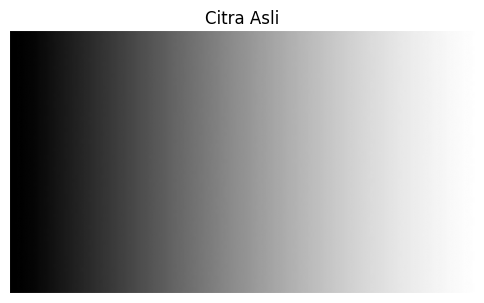

In [ ]:

filename = '/content/drive/MyDrive/pcvk_3/gradient.jpg'

img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

if img is None:
    print("Gambar tidak ditemukan. Periksa kembali lokasi file.")
else:
    print("Ukuran citra:", img.shape)
    plt.figure(figsize=(6, 4))
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title('Citra Asli')
    plt.axis('off')
    plt.show()

In [ ]:

thresh = 200
maxval = 255
# Binary Threshold
binary = np.where(img > thresh, maxval, 0).astype(np.uint8)
# Binary Inverse Threshold
binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)
# Truncate Threshold
trunc = np.where(img > thresh, thresh, img).astype(np.uint8)
# Threshold To Zero
tozero = np.where(img > thresh, img, 0).astype(np.uint8)
# Threshold To Zero Inverse
tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

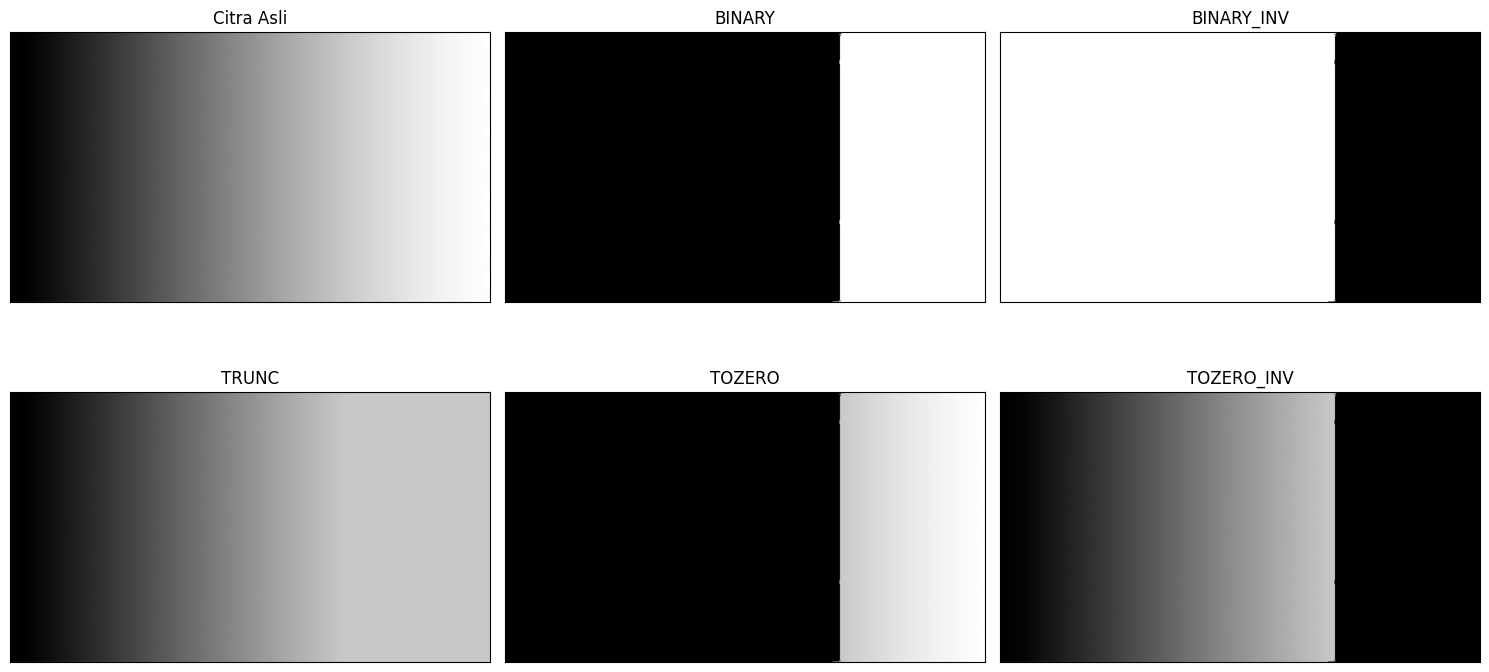

In [ ]:
titles = [
    'Citra Asli',
    'BINARY',
    'BINARY_INV',
    'TRUNC',
    'TOZERO',
    'TOZERO_INV'
]

images = [
    img,
    binary,
    binary_inv,
    trunc,
    tozero,
    tozero_inv
]

plt.figure(figsize=(15, 8))

for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

Ukuran citra: (423, 419)


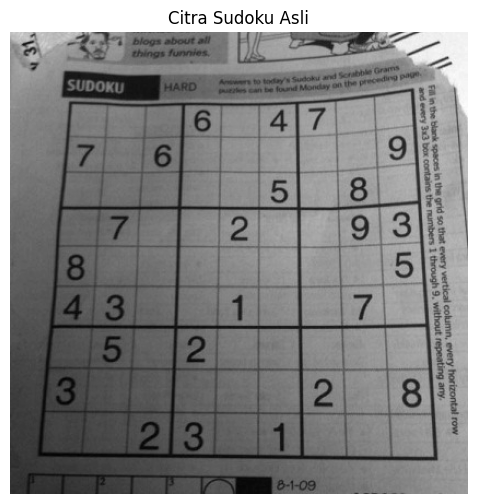

In [ ]:
filename = '/content/drive/MyDrive/pcvk_3/sudoku-original.jpg'

sudoku = cv.imread(filename, cv.IMREAD_GRAYSCALE)

if sudoku is None:
    print("Gambar Sudoku tidak ditemukan. Periksa lokasi file.")
else:
    print("Ukuran citra:", sudoku.shape)

    plt.figure(figsize=(6, 6))
    plt.imshow(sudoku, cmap='gray')
    plt.title('Citra Sudoku Asli')
    plt.axis('off')
    plt.show()

In [ ]:
block_size = 11
C = 2
sigma = 2
thresh = 127

In [ ]:
global_thresh = np.where(
    sudoku > thresh, 255, 0
).astype(np.uint8)

In [ ]:
gray = sudoku.astype(np.float64)

h, w = gray.shape
pad = block_size // 2

padded = np.pad(
    gray, ((pad, pad), (pad, pad)), mode='reflect'
)

integral = np.pad(
    padded.cumsum(axis=0).cumsum(axis=1),
    ((1, 0), (1, 0)),
    mode='constant'
)

window_sum = (
    integral[block_size:, block_size:]
    - integral[:-block_size, block_size:]
    - integral[block_size:, :-block_size]
    + integral[:-block_size, :-block_size]
)

local_mean = window_sum / (block_size * block_size)

local_thresh_mean = local_mean - C

adaptive_mean = np.where(
    gray > local_thresh_mean, 255, 0
).astype(np.uint8)

In [ ]:
coords = np.arange(-pad, pad + 1)
xx, yy = np.meshgrid(coords, coords)

gaussian_kernel = np.exp(
    -(xx**2 + yy**2) / (2 * sigma**2)
)

gaussian_kernel /= gaussian_kernel.sum()

padded_gaussian = np.pad(
    gray, ((pad, pad), (pad, pad)), mode='reflect'
)

local_mean_gaussian = np.zeros_like(gray)

for i in range(block_size):
    for j in range(block_size):
        weight = gaussian_kernel[i, j]

        local_mean_gaussian += (
            weight
            * padded_gaussian[
                i:i+h,
                j:j+w
            ]
        )

local_thresh_gaussian = local_mean_gaussian - C

adaptive_gaussian = np.where(
    gray > local_thresh_gaussian, 255, 0
).astype(np.uint8)

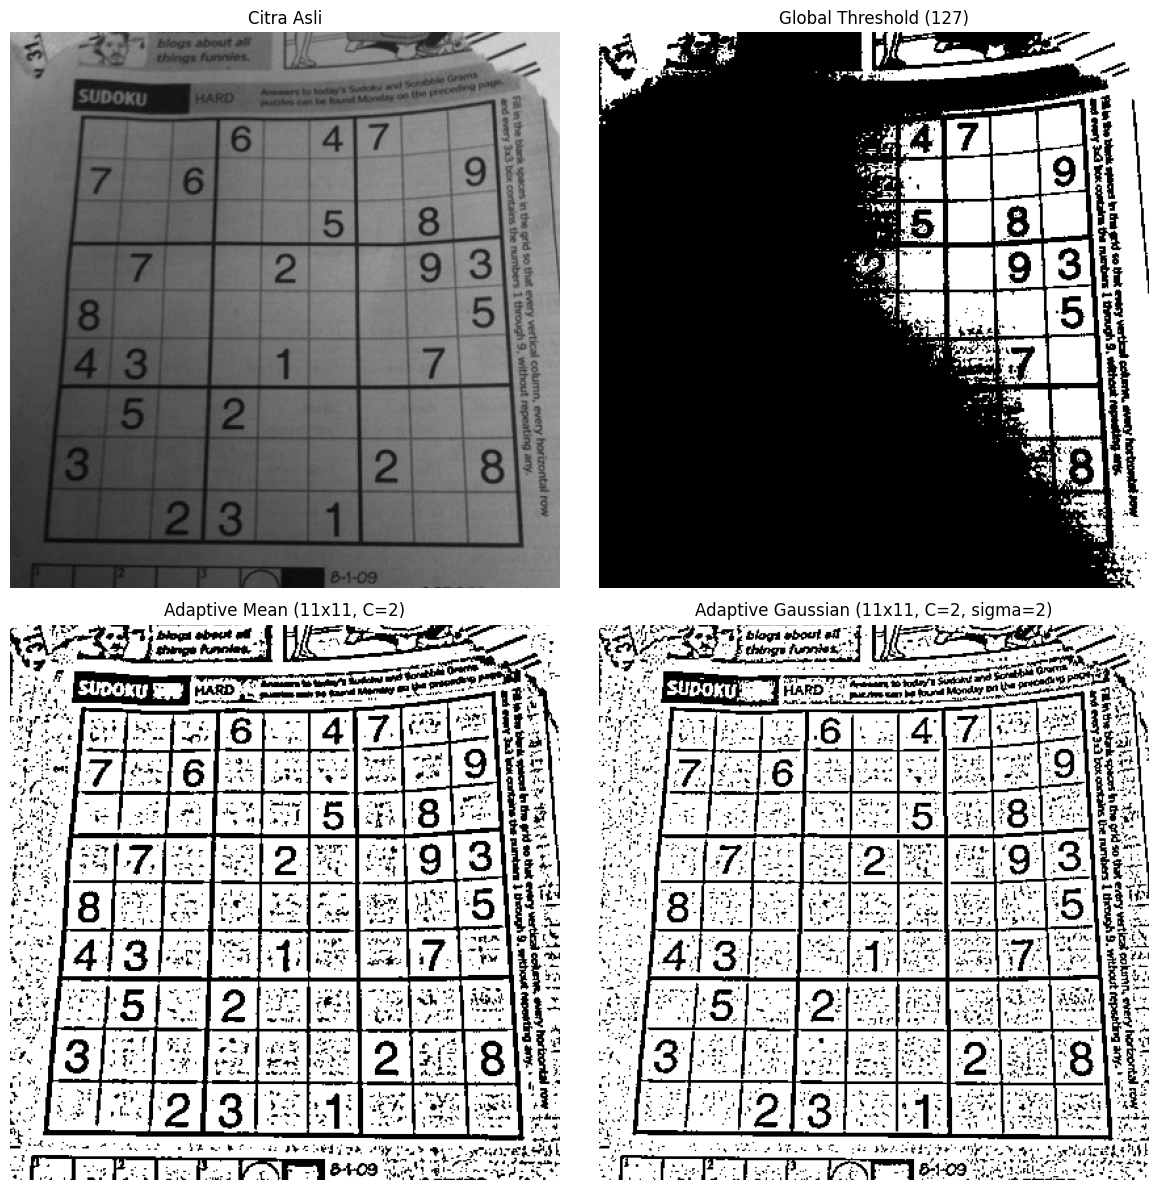

In [ ]:
titles = [
    'Citra Asli',
    'Global Threshold (127)',
    'Adaptive Mean (11x11, C=2)',
    'Adaptive Gaussian (11x11, C=2, sigma=2)'
]

images = [
    sudoku,
    global_thresh,
    adaptive_mean,
    adaptive_gaussian
]

plt.figure(figsize=(12, 12))

for i in range(len(images)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

Ukuran citra Lena: (512, 512)


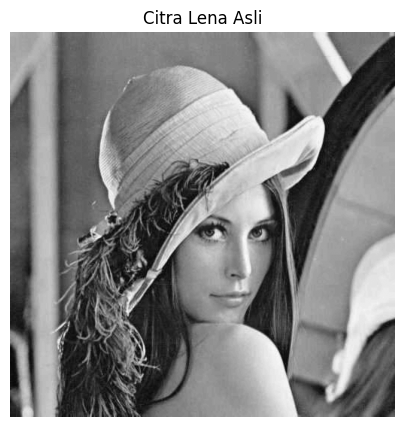

In [ ]:
filename = '/content/drive/MyDrive/pcvk_3/images/244107020024/lena_lc.jpg'

lena = cv.imread(filename, cv.IMREAD_GRAYSCALE)

if lena is None:
    print("Gambar Lena tidak ditemukan. Periksa lokasi file.")
else:
    print("Ukuran citra Lena:", lena.shape)

    plt.figure(figsize=(5, 5))
    plt.imshow(lena, cmap='gray')
    plt.title('Citra Lena Asli')
    plt.axis('off')
    plt.show()

/tmp/ipykernel_17496/3373632731.py:20: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_17496/3373632731.py:21: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


125


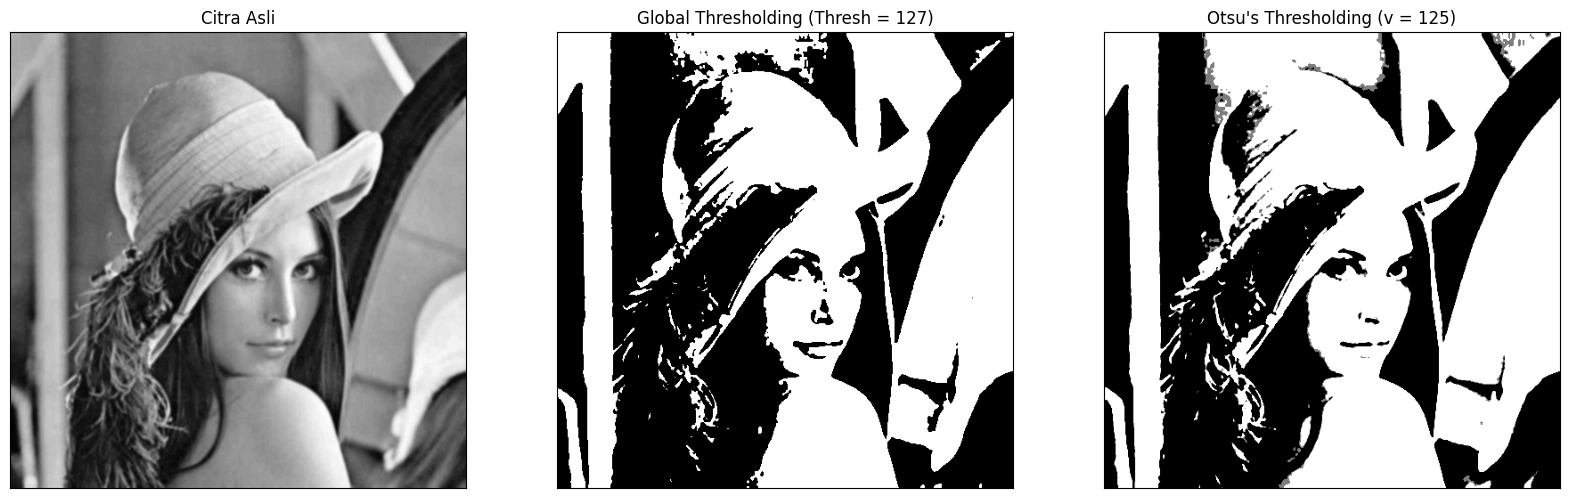

'\nMengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam\nsemuan? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas\n(Thresh) supaya gambar Lena ini masih terlihat? karena citra lena memiliki kontras rendah dimana sebaran nilai intensitas piksel hanya pada rentang sempit antar 85 - 108 saja.\nGaris ambang batas global T = 27 berada jauh disebelah kanan kelompok data\n'

In [ ]:
filename = ('/content/drive/MyDrive/pcvk_3/images/244107020024/lena_lc.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img, (5,5),0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ") + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

'''
Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam
semuan? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas
(Thresh) supaya gambar Lena ini masih terlihat? karena citra lena memiliki kontras rendah dimana sebaran nilai intensitas piksel hanya pada rentang sempit antar 85 - 108 saja.
Garis ambang batas global T = 27 berada jauh disebelah kanan kelompok data
'''

Nilai Otsu Threshold: 166


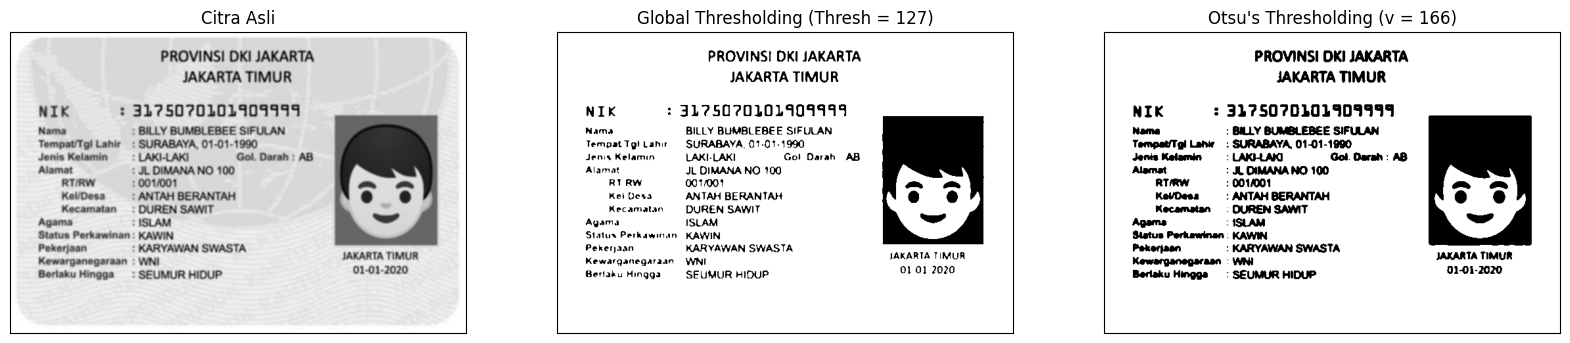

In [ ]:
# Ganti path file ke file ktp_fulan Anda
filename = ('/content/drive/MyDrive/pcvk_3/ktp_fulan.jpg')
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        # Hindari pembagian dengan nol jika kelas kosong
        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print("Nilai Otsu Threshold:", final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

# 3 Citra yang ditampilkan sesuai modul: Asli (Grayscale), Global Thresholding, dan Otsu's
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])
plt.show()

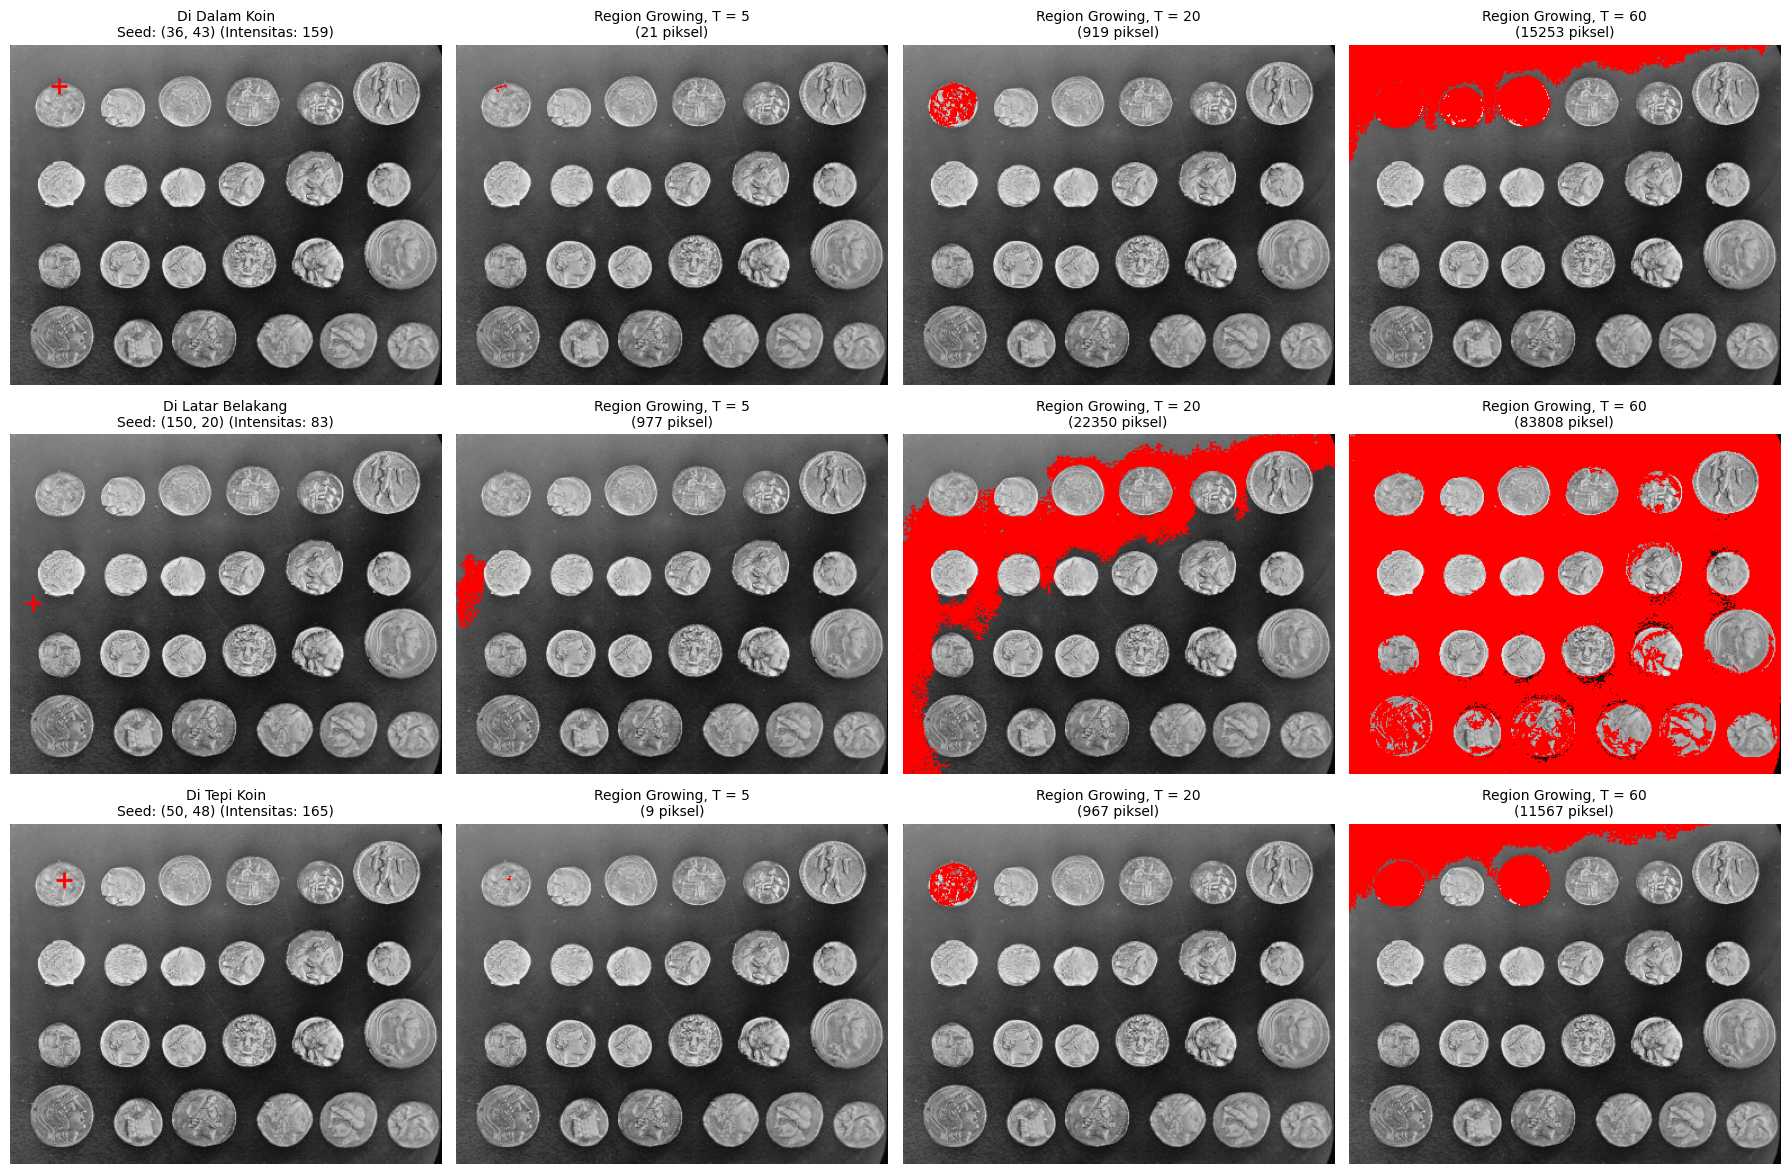

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()

seeds = [
    {"titik": (36, 43),  "label": "Di Dalam Koin"},
    {"titik": (150, 20), "label": "Di Latar Belakang"},
    {"titik": (50, 48),  "label": "Di Tepi Koin"}
]

thresholds = [5, 20, 60]

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(18, 12))

for row_idx, s in enumerate(seeds):
    seed_pt = s["titik"]
    seed_val = gray[seed_pt]

    axes[row_idx, 0].imshow(gray, cmap='gray')
    axes[row_idx, 0].plot(seed_pt[1], seed_pt[0], 'r+', markersize=12, markeredgewidth=2)
    axes[row_idx, 0].set_title(f"{s['label']}\nSeed: {seed_pt} (Intensitas: {seed_val})", fontsize=10)
    axes[row_idx, 0].axis('off')

    for col_idx, T in enumerate(thresholds):

        mask = flood(gray, seed_point=seed_pt, tolerance=T, connectivity=1)
        total_pixels = np.sum(mask)

        overlay = np.stack([gray] * 3, axis=-1)
        overlay[mask] = [255, 0, 0]  # Warna merah (R=255, G=0, B=0)

        ax = axes[row_idx, col_idx + 1]
        ax.imshow(overlay)
        ax.set_title(f"Region Growing, T = {T}\n({total_pixels} piksel)", fontsize=10)
        ax.axis('off')

plt.tight_layout()
plt.show()

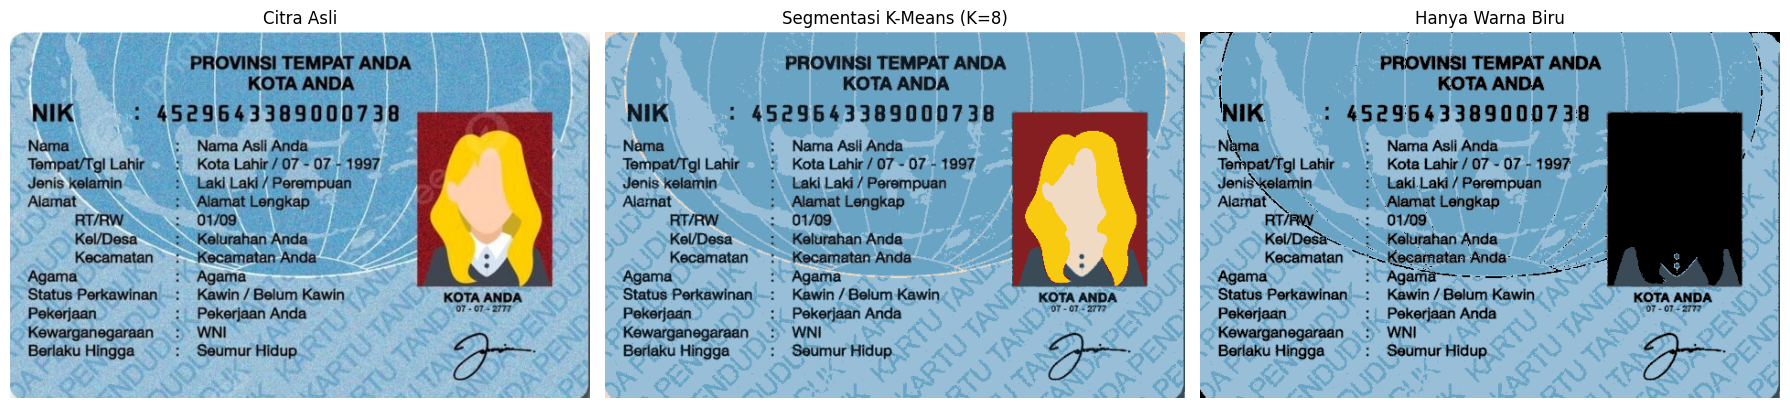

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

filename = '/content/drive/MyDrive/pcvk_3/ktp_fulani.jpg'
img_bgr = cv.imread(filename)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

Z = img_rgb.reshape((-1, 3))
Z = np.float32(Z)

k = 8
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)

centers = np.uint8(kmeans.cluster_centers_)
labels = kmeans.labels_
segmented_img = centers[labels.flatten()].reshape(img_rgb.shape)

segmented_hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H = segmented_hsv[:, :, 0]
S = segmented_hsv[:, :, 1]
V = segmented_hsv[:, :, 2]

mask_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

hanya_biru = np.zeros_like(segmented_img)
hanya_biru[mask_biru] = segmented_img[mask_biru]

titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
citra_list = [img_rgb, segmented_img, hanya_biru]

plt.figure(figsize=(18, 6))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra_list[i])
    plt.title(titles[i], fontsize=12)
    plt.axis('off')

plt.tight_layout()
plt.show()

**TUGAS KELOMPOK**

In [ ]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import pandas as pd
import re

from pytesseract import Output

print("Versi Tesseract:", pytesseract.get_tesseract_version())
print("Bahasa tersedia:", pytesseract.get_languages(config=''))


Versi Tesseract: 5.3.4
Bahasa tersedia: ['eng', 'ind', 'osd']


=== KTP 1 ===
Ukuran citra: (553, 830, 3)
Nilai Threshold Otsu: 111.0
------------------------------
=== KTP 2 ===
Ukuran citra: (785, 1370, 3)
Nilai Threshold Otsu: 97.0
------------------------------
=== KTP 3 ===
Ukuran citra: (1008, 1599, 3)
Nilai Threshold Otsu: 175.0
------------------------------


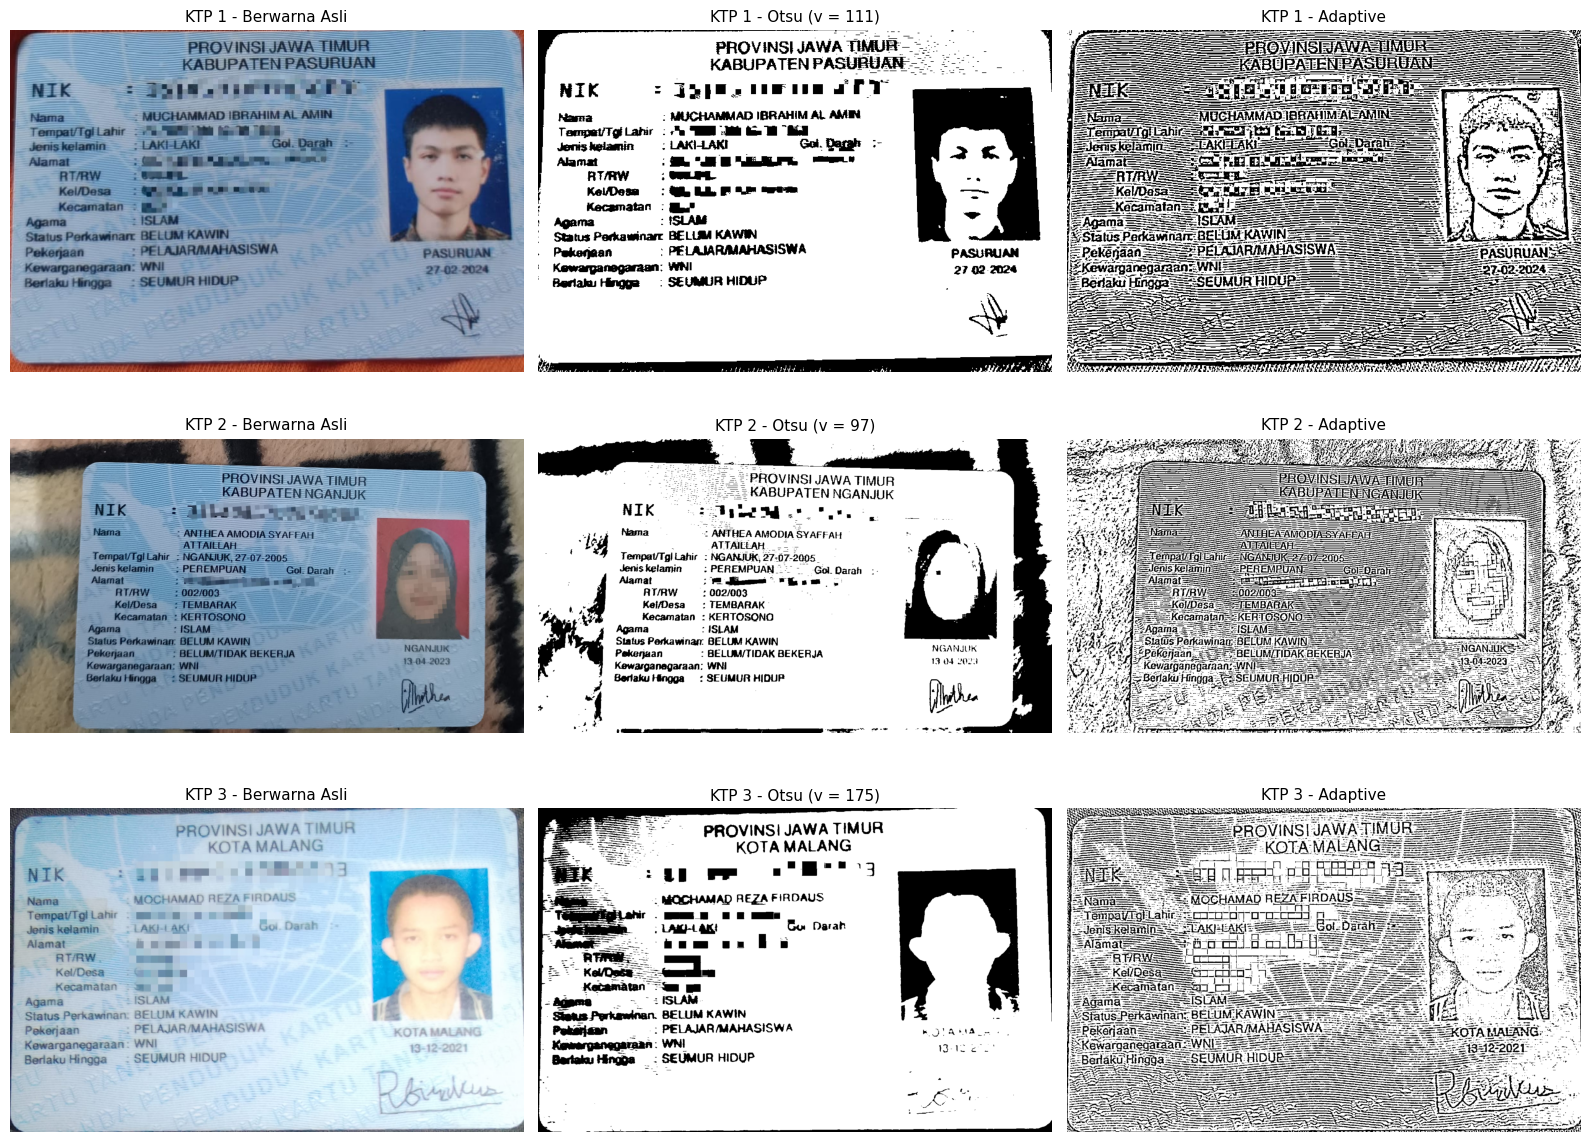

In [39]:
import cv2 as cv
import matplotlib.pyplot as plt

file_name = {
    'KTP 1': '/content/drive/MyDrive/pcvk_3/KTP_IBRA.jpeg',
    'KTP 2': '/content/drive/MyDrive/pcvk_3/KTP_ANTHEA.jpeg',
    'KTP 3': '/content/drive/MyDrive/pcvk_3/KTP_REZA.jpeg'
}

plt.figure(figsize=(16, 12))
plot_idx = 1

for label, path in file_name.items():

    original = cv.imread(path)

    if original is None:
        print(f"Peringatan: Gambar {label} tidak ditemukan di path: {path}")
        continue

    gray = cv.cvtColor(original, cv.COLOR_BGR2GRAY)

    img_color = original.copy()

    threshold_otsu, img_otsu = cv.threshold(
        gray, 0, 255,
        cv.THRESH_BINARY + cv.THRESH_OTSU
    )

    img_adaptive = cv.adaptiveThreshold(
        gray,
        255,
        cv.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv.THRESH_BINARY,
        11,
        2
    )

    print(f"=== {label} ===")
    print("Ukuran citra:", img_color.shape)
    print("Nilai Threshold Otsu:", threshold_otsu)
    print("-" * 30)

    titles = [
        f'{label} - Berwarna Asli',
        f'{label} - Otsu (v = {int(threshold_otsu)})',
        f'{label} - Adaptive'
    ]
    images = [img_color, img_otsu, img_adaptive]

    for title, image in zip(titles, images):
        plt.subplot(len(file_name), 3, plot_idx)
        if len(image.shape) == 3:
            plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
        else:
            plt.imshow(image, cmap='gray', vmin=0, vmax=255)
        plt.title(title, fontsize=11)
        plt.axis('off')
        plot_idx += 1

plt.tight_layout()
plt.show()

In [46]:
ocr_images = {
    'Berwarna': img_rgb,
    'Otsu': img_otsu,
    'Adaptive': img_adaptive
}

lang = 'ind'
config = '--psm 6'

ocr_results = {}

for name, image in ocr_images.items():
    if len(image.shape) == 3:
        image_input = cv.cvtColor(image, cv.COLOR_BGR2RGB)
    else:
        image_input = image

    text_result = pytesseract.image_to_string(
        image_input,
        lang=lang,
        config=config
    )

    ocr_results[name] = text_result

    print('=' * 50)
    print(name)
    print('=' * 50)
    print(text_result)
    print()


Berwarna
Ia EROvinSI Jawa TIMUR |
AS 53 TE KABUPATEN NGANJUK —
Te 5. —
NIK o Jam raw
WNI Hama -———- ANTHEAAMODIASYAFFAH
Ko 3 MEME 2. 3
"TT Tempat/Tgi Lahir : NGANJUK, 2707-2005 MN
Jenis kelamin — -—- PEREMPUAN — — Gol. Darah :- ,
Alamat“ Su BN an, 4
ATAW 002093 —— 5-5
bi Anh Kecamatan : KERTOSONO-————— — :
SI Agama 2ISLAM — — 25. .
Pr. Lu Status Perkawinan BELUM KAWIN : NGANJUK
/ Pekerjaan ? BELUM/TIDAK BEKERJA NN Iga
| | Kewarganegaraan: WNI 5 - '
Berlaku Hingga « SEUMUR HIDUP 2 5
aa aw . —


Otsu
— aa SAN asi PROVINSI JAWA TIMUR
LE 35 33 KABUPATEN NGANJUK
NIK PA Bia MN Ne
Hd Nama : ANTHEA AMODIA SYAFFAH »
: lg . ATTAIELAH » S5
: : Tempat/Tgi Lahir : NGANJUK. 27-07-2005. ,
Jeniskelamin — : PEREMPUAN” - “Gol Darah -- . "
: Alamat ia ai LK
AT/RW 1 002/003 - . :
00 hp Kei/Desa —: TEMBARAK :
Bean Kecamatan : KERTOSONO i
| Agama : ISLAM
: Status Perkawinan BELUM KAWIN NGANJUK
( Pekerjaan : BELUM/TIDAK BEKERJA Pa 04 053 .
x Kewarganegaraan: WNI N
j Berlaku Hingga: SEUMUR HIDUP
. - Avika
4 .

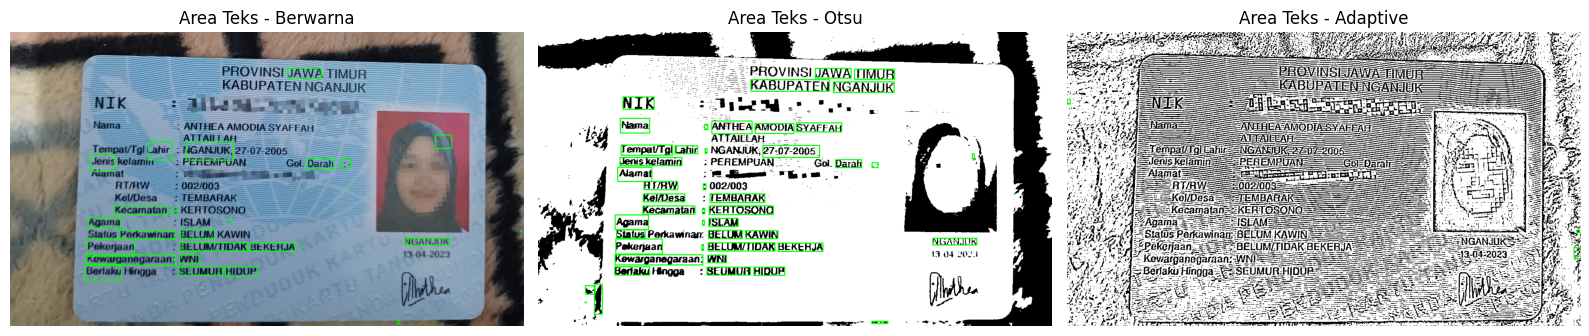

In [44]:
from pytesseract import Output

plt.figure(figsize=(16, 6))

for i, (name, image) in enumerate(ocr_images.items()):

    data = pytesseract.image_to_data(image, lang=lang, config=config, output_type=Output.DICT)


    if len(image.shape) == 2:
        img_box = cv.cvtColor(image, cv.COLOR_GRAY2RGB)
    else:
        img_box = image.copy()

    n_boxes = len(data['text'])
    for j in range(n_boxes):
        conf = int(data['conf'][j])
        text = data['text'][j].strip()

        if conf > 60 and text != '':
            x, y, w, h = data['left'][j], data['top'][j], data['width'][j], data['height'][j]
            cv.rectangle(img_box, (x, y), (x + w, y + h), (0, 255, 0), 2)

    plt.subplot(1, 3, i + 1)
    plt.imshow(img_box)
    plt.title(f"Area Teks - {name}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:

reference_items = [
    'PROVINSI',
    'JAWA',
    'TIMUR',
    'KOTA',
    'KELAMIN',
    'ISLAM',
    'PELAJAR',
    'INDONESIA',
    'BERLAKU',
    'SEUMUR'
]

def normalize_text(text):
    return ' '.join(str(text).strip().lower().split())

rows = []

for item in reference_items:
    row = {'Teks sebenarnya': item}

    for name, text in ocr_results.items():
        normalized_item = normalize_text(item)
        normalized_ocr = normalize_text(text)

        import re
        pattern = (
            r'(?<!\w)' +
            re.escape(normalized_item) +
            r'(?!\w)'
        )

        match = bool(re.search(pattern, normalized_ocr))
        row[name] = 'Cocok' if match else 'Tidak cocok'

    rows.append(row)

comparison_df = pd.DataFrame(rows)
display(comparison_df)

,Teks sebenarnya,Berwarna,Otsu,Adaptive
0,PROVINSI,Cocok,Cocok,Tidak cocok
1,JAWA,Tidak cocok,Cocok,Tidak cocok
2,TIMUR,Tidak cocok,Cocok,Tidak cocok
3,KOTA,Cocok,Tidak cocok,Tidak cocok
4,KELAMIN,Cocok,Tidak cocok,Tidak cocok
5,ISLAM,Tidak cocok,Cocok,Tidak cocok
6,PELAJAR,Tidak cocok,Tidak cocok,Tidak cocok
7,INDONESIA,Tidak cocok,Tidak cocok,Tidak cocok
8,BERLAKU,Cocok,Cocok,Tidak cocok
9,SEUMUR,Cocok,Cocok,Tidak cocok


In [ ]:
summary_rows = []

for name in ocr_images:
    correct_count = sum(
        row[name] == 'Cocok'
        for row in rows
    )

    accuracy = correct_count / len(reference_items) * 100

    confs = confidence_results[name]
    avg_confidence = np.mean(confs) if confs else np.nan

    summary_rows.append({
        'Citra masukan OCR': name,
        'Item terbaca tepat': f'{correct_count}/{len(reference_items)}',
        'Kecocokan (%)': round(accuracy, 2),
        'Rata-rata confidence': round(avg_confidence, 2)
        if not np.isnan(avg_confidence) else 'Tidak ada data'
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna,5/10,50.0,74.36
1,Otsu,6/10,60.0,50.18
2,Adaptive,0/10,0.0,14.73


1. Citra Paling Tepat
Citra otsu menghasilkan pembacaan yang paling tepat dengan kecocokan 6/10 (60%), menjadikannya yang terbaik dibandingkan dengan metode lainnya.
2. Contoh Kesalahan Pembacaan
Terdapat kesalahan OCR seperti "Atthaillah" yang terbaca sebagai "ATTAIELAH", karena kemiripan bentuk karakter.
3. Pengaruh Segmentasi terhadap Akurasi
Tidak selalu demikian. Segmentasi [Otsu/Adaptive] memiliki kecocokan 60 dan 0 persen%, sementara citra asli mencapai 50 persen. Thresholding yang kurang tepat dapat memutus goresan huruf dan merusak detail teks.
4. Pengaruh Latar Belakang
Warna atau pola latar belakang dapat mengurangi kontras antara teks dan area sekitarnya, menyebabkan noise yang membuat Tesseract salah dalam menebak atau gagal mendeteksi huruf.
5. Hubungan Nilai Confidence dan Akurasi
Tidak. Metode Berwarna Asli memiliki rata-rata kepercayaan tertinggi sebesar 74,36, tetapi kecocokan terbaik dicapai oleh metode Otsu, yaitu 60% atau 6 dari 10 item yang terbaca dengan tepat. Di sisi lain, metode Adaptive memiliki rata-rata kepercayaan sebesar 14,73 dengan kecocokan 0%. Hal ini mengindikasikan bahwa rata-rata kepercayaan yang tinggi tidak selalu menjamin hasil OCR yang paling akurat.